# Лабораторная работа №2: классификация

**Цель:** предсказать выживание пассажира Titanic (`Survived`: 1 — выжил, 0 — погиб), сравнить пять алгоритмов с Dummy baseline и проанализировать ошибки.
Основная метрика — **F1 для класса 1**, требуемый порог — **F1 > 0.70**.

[Задание](lab02.pdf). Данные: `data/Titanic-Dataset.csv` — 891 пассажир, 12 столбцов; [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset).

Выполните ячейки сверху вниз с рабочей папкой `classification`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 4)

## 1. Первичный анализ данных

`Pclass` — класс билета, `Sex` — пол, `Age` — возраст, `SibSp` — число братьев, сестёр и супругов на борту,
`Parch` — число родителей и детей, `Fare` — стоимость билета, `Embarked` — порт посадки.
Остальные столбцы описывают идентификатор пассажира, имя, номер билета и каюту.

In [2]:
df = pd.read_csv(Path('data/Titanic-Dataset.csv'))
print('Размер:', df.shape)
display(df.head())
display(pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'пропуски': df.isna().sum(),
    'пропуски, %': df.isna().mean().mul(100).round(1),
    'уникальных значений': df.nunique(),
}))
print('Полных дубликатов:', df.duplicated().sum())
print('Повторяющихся PassengerId:', df['PassengerId'].duplicated().sum())
display(df['Survived'].value_counts().sort_index().to_frame('пассажиров').assign(
    доля=df['Survived'].value_counts(normalize=True).sort_index()
).round(3))

Размер: (891, 12)
Полных дубликатов: 0
Повторяющихся PassengerId: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,тип,пропуски,"пропуски, %",уникальных значений
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


,пассажиров,доля
Survived,,
0,549,0.616
1,342,0.384


**Выводы.** Выжили 342 пассажира (38.4%), погибли 549 (61.6%). Дисбаланс умеренный, но прогноз «все погибли» уже даёт Accuracy около 0.62 и не находит ни одного выжившего.
Полных дубликатов и повторяющихся ID нет. Пропущены 177 возрастов, 687 кают (77.1%) и 2 порта посадки.

Исключаю `PassengerId` и `Name`: они идентифицируют пассажира. `Ticket` может связывать конкретных пассажиров и группы;
для простого решения также исключаю его. `Cabin` имеет много пропусков и редких значений, поэтому тоже исключаю.
`Survived` используется только как ответ. `Pclass` числовой по записи, но обозначает категорию, поэтому кодирую его как категориальный.

## 2. Обучающая и тестовая выборки

Разбиение 80/20 со стратификацией сохраняет доли классов. Для всех моделей используются одни и те же строки и `random_state=42`.
Дальнейший EDA и выбор лучшей модели выполняются только на train. Локальный test используется для финальной оценки в разделе 7.
Прохождение порога на локальном разбиении не гарантирует его прохождения на единой тестовой выборке группы.

In [3]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
features = numeric_features + categorical_features
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)
print('train:', X_train.shape, 'test:', X_test.shape)
display(pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).sort_index().round(3))

train: (712, 7) test: (179, 7)


,train,test
Survived,,
0,0.617,0.615
1,0.383,0.385


## 3. Исследовательский анализ (только train)

,Age,SibSp,Parch,Fare
count,575.00,712.00,712.00,712.00
mean,29.81,0.49,0.39,31.82
std,14.49,1.06,0.84,48.06
min,0.42,0.00,0.00,0.00
25%,21.00,0.00,0.00,7.90
50%,28.50,0.00,0.00,14.45
75%,39.00,1.00,0.00,31.00
max,80.00,8.00,6.00,512.33


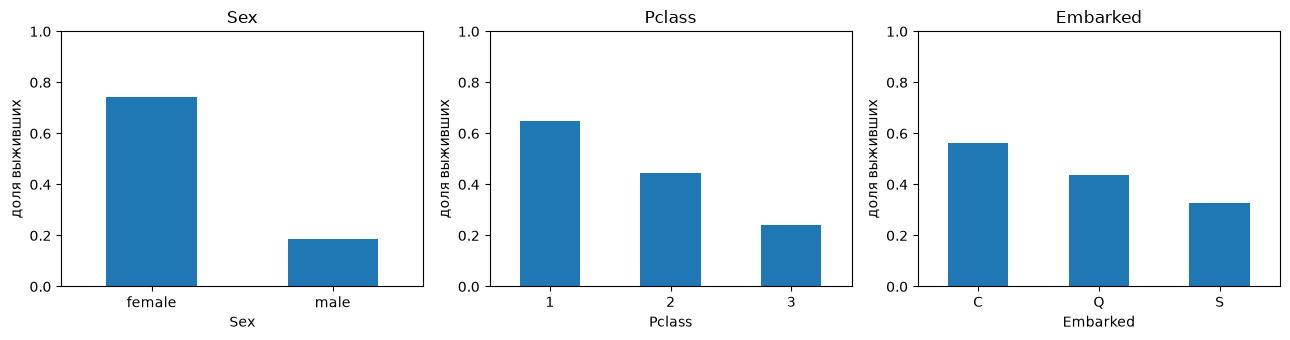

,count,mean
Age,,
"(-0.001, 12.0]",55,0.600
"(12.0, 18.0]",53,0.415
"(18.0, 40.0]",346,0.382
"(40.0, 60.0]",105,0.410
"(60.0, inf]",16,0.188


,count,mean
Sex,,
female,253,0.743
male,459,0.185


,count,mean
Pclass,,
1,171,0.649
2,150,0.447
3,391,0.243


In [4]:
train = X_train.assign(Survived=y_train)
display(train[numeric_features].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for column, ax in zip(['Sex', 'Pclass', 'Embarked'], axes):
    train.groupby(column)['Survived'].mean().plot.bar(ax=ax, rot=0)
    ax.set(title=column, ylabel='доля выживших', ylim=(0, 1))
plt.tight_layout()
plt.show()

age_group = pd.cut(train['Age'], [0, 12, 18, 40, 60, np.inf], include_lowest=True)
display(train.groupby(age_group, observed=True)['Survived'].agg(['count', 'mean']).round(3))
display(train.groupby('Sex')['Survived'].agg(['count', 'mean']).round(3))
display(train.groupby('Pclass')['Survived'].agg(['count', 'mean']).round(3))

**Выводы EDA.** Женщины выживали заметно чаще мужчин; у пассажиров первого класса доля выживших выше, чем у третьего.
У детей до 12 лет доля выживших выше, чем у взрослых 18–40 лет. Поэтому ожидаю высокую важность пола и класса билета;
возраст тоже может помогать. Различия по порту могут отражать состав пассажиров, а не самостоятельное влияние порта.
`Fare` и `Age` имеют разные масштабы, а у стоимости билета есть большие значения: это существенно для методов, использующих расстояния.

## 4. Подготовка признаков

Числовые пропуски заполняю медианой: она меньше среднего чувствительна к большим значениям.
Категориальные — наиболее частой категорией; затем применяю One-Hot Encoding без искусственного порядка категорий.
Неизвестная при обучении категория не приводит к ошибке (`handle_unknown='ignore'`).

Для SVM и KNN числовые признаки стандартизую: иначе стоимость билета может доминировать в расстояниях и RBF-ядре SVM.
Деревья сравнивают значения с порогами, поэтому масштабирование им не требуется.
Все преобразования находятся внутри `Pipeline`: медианы, категории и параметры масштаба вычисляются только на обучающей части,
в том числе отдельно внутри каждого блока кросс-валидации.

In [5]:
def make_preprocessor(scale=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(numeric_steps), numeric_features),
        ('cat', make_pipeline(
            SimpleImputer(strategy='most_frequent'),
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ), categorical_features),
    ])


def make_model(estimator, scale=False):
    return make_pipeline(make_preprocessor(scale), estimator)

## 5. Метрики и Dummy baseline

Положительный класс — выживший пассажир (`1`).

- **TP:** выжил, модель предсказала «выжил»; **TN:** погиб, модель предсказала «погиб».
- **FP:** погиб, но модель предсказала «выжил» — ложный положительный прогноз.
- **FN:** выжил, но модель предсказала «погиб» — пропущенный выживший.

$$Accuracy = \frac{TP+TN}{N},\quad Precision = \frac{TP}{TP+FP},\quad Recall = \frac{TP}{TP+FN},\quad F1 = \frac{2TP}{2TP+FP+FN}.$$

Precision отвечает, какая доля предсказанных выживших действительно выжила; Recall — какую долю всех выживших нашли.
F1 учитывает оба вида ошибок. Accuracy может скрывать плохое распознавание меньшего класса.
Если модель не предсказывает ни одного выжившего, Precision считаю равным 0 (`zero_division=0`).

Baseline всегда выбирает наиболее частый класс. До остальных моделей оцениваю его на train;
на общем test он будет оценён вместе с пятью моделями по тем же метрикам.

In [6]:
def metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
display(pd.Series(metrics(y_train, baseline.predict(X_train)), name='Baseline: train').round(3))

Accuracy     0.617
Precision    0.000
Recall       0.000
F1           0.000
Name: Baseline: train, dtype: float64

**Вывод.** Baseline предсказывает всем класс 0. Accuracy около 0.62, но Precision, Recall и F1 равны нулю:
выжившие полностью пропущены. Сравнивать обученные модели только по Accuracy было бы недостаточно.

## 6. Пять моделей и выбор по train

- **Decision Tree:** последовательность правил по признакам. Ограничиваю глубину до 5 и минимум 5 объектов в листе, чтобы уменьшить запоминание train.
- **Random Forest:** 200 деревьев на случайных подвыборках; их голосование снижает разброс одного дерева. Минимум 2 объекта в листе.
- **Gradient Boosting:** 100 неглубоких деревьев последовательно исправляют ошибки ансамбля; остальные параметры стандартные.
- **SVM:** нелинейная граница с RBF-ядром, `C=1`; использует стандартизованные числовые признаки.
- **KNN:** голосование 5 ближайших соседей; числовые признаки также стандартизованы.

Параметры заданы заранее, без поиска по test. Лучшую модель выбираю по среднему F1 на 5 блоках стратифицированной кросс-валидации train.
`CV std` показывает разброс F1 между блоками, а не доверительный интервал. Порог принятия решения не подбираю: использую `predict` моделей.

In [7]:
models = {
    'Baseline': baseline,
    'Decision Tree': make_model(DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE,
    )),
    'Random Forest': make_model(RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1,
    )),
    'Gradient Boosting': make_model(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    'SVM': make_model(SVC(C=1.0, kernel='rbf'), scale=True),
    'KNN': make_model(KNeighborsClassifier(n_neighbors=5), scale=True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    cv_results[name] = {'CV F1': scores.mean(), 'CV std': scores.std()}
cv_summary = pd.DataFrame(cv_results).T
best_name = cv_summary.drop(index='Baseline')['CV F1'].idxmax()
display(cv_summary.sort_values('CV F1', ascending=False).round(3))
print('Выбрана до оценки на test:', best_name)

Выбрана до оценки на test: Gradient Boosting


,CV F1,CV std
Gradient Boosting,0.753,0.031
SVM,0.745,0.031
Random Forest,0.741,0.040
Decision Tree,0.721,0.013
KNN,0.718,0.016
Baseline,0.000,0.000


**Вывод.** По CV выбран Gradient Boosting: средний F1 = 0.753, разброс между блоками 0.031.
Ближайшие результаты — SVM (0.745) и Random Forest (0.741). Различия небольшие относительно разброса,
поэтому этот эксперимент не доказывает устойчивое превосходство бустинга. Выбор сделан до оценки test.

## 7. Итоговая оценка на test

Теперь один раз получаю предсказания на общем test для каждой модели и сохраняю их для всех дальнейших таблиц и графиков.
Результаты test используются для отчёта и анализа ошибок; модель, признаки и параметры по ним не меняются.

In [8]:
fitted_models, predictions, results = {}, {}, {}
for name, model in models.items():
    fitted = clone(model).fit(X_train, y_train)
    pred = fitted.predict(X_test)
    fitted_models[name] = fitted
    predictions[name] = pred
    results[name] = metrics(y_test, pred)
    results[name]['train F1'] = f1_score(y_train, fitted.predict(X_train), zero_division=0)

summary = pd.DataFrame(results).T.join(cv_summary)
summary['F1 > 0.70'] = summary['F1'] > 0.70
display(summary.round(3))
print('Лучшая по CV:', best_name)
print('Максимальный F1 на локальном test:', summary['F1'].idxmax())
print('Порог прошли:', ', '.join(summary.index[summary['F1 > 0.70']]))

Лучшая по CV: Gradient Boosting
Максимальный F1 на локальном test: KNN
Порог прошли: Random Forest, Gradient Boosting, SVM, KNN


,Accuracy,Precision,Recall,F1,train F1,CV F1,CV std,F1 > 0.70
Baseline,0.615,0.000,0.000,0.000,0.000,0.000,0.000,False
Decision Tree,0.771,0.733,0.638,0.682,0.802,0.721,0.013,False
Random Forest,0.804,0.815,0.638,0.715,0.879,0.741,0.040,True
Gradient Boosting,0.793,0.786,0.638,0.704,0.865,0.753,0.031,True
SVM,0.816,0.821,0.667,0.736,0.779,0.745,0.031,True
KNN,0.821,0.814,0.696,0.750,0.798,0.718,0.016,True


**Результаты и различия моделей.**

- **Decision Tree:** F1 на train 0.802, на test 0.682. Разрыв около 0.12 указывает на признаки переобучения,
  несмотря на ограничение глубины и размера листа. Модель лучше baseline, но порог не проходит.
- **Random Forest:** F1 = 0.715, лучше одиночного дерева. Усреднение деревьев уменьшает нестабильность отдельных правил.
  Разрыв с train (0.879) остаётся заметным, поэтому лес также не свободен от переобучения.
- **Gradient Boosting:** F1 = 0.704; на этом test немного хуже леса (0.715), хотя по CV был лучше.
  F1 на train 0.865: ансамбль тоже частично подстраивается под обучающие данные.
- **SVM:** F1 = 0.736, Precision = 0.821, Recall = 0.667. Стандартизация делает числовые признаки сопоставимыми,
  а RBF-ядро позволяет учитывать нелинейные границы. Разрыв с train (0.779) меньше, чем у моделей на деревьях.
- **KNN:** максимальный F1 на локальном test — 0.750, Precision = 0.814, Recall = 0.696.
  Здесь соседние пассажиры дают полезный прогноз; меньшая CV-оценка (0.718) показывает, что положение модели в рейтинге зависит от разбиения.

**Порог F1 > 0.70 прошли Random Forest, Gradient Boosting, SVM и KNN.** Все пять моделей превосходят baseline с F1 = 0.
Различия объясняются сложностью границ, устойчивостью ансамблей и составом небольшой тестовой выборки.
Максимум на одном test не гарантирует преимущество на других данных; выбранной по train моделью остаётся Gradient Boosting.

### Матрицы ошибок всех моделей

Строки — настоящий класс, столбцы — прогноз. Слева сверху TN, справа сверху FP, слева снизу FN, справа снизу TP.

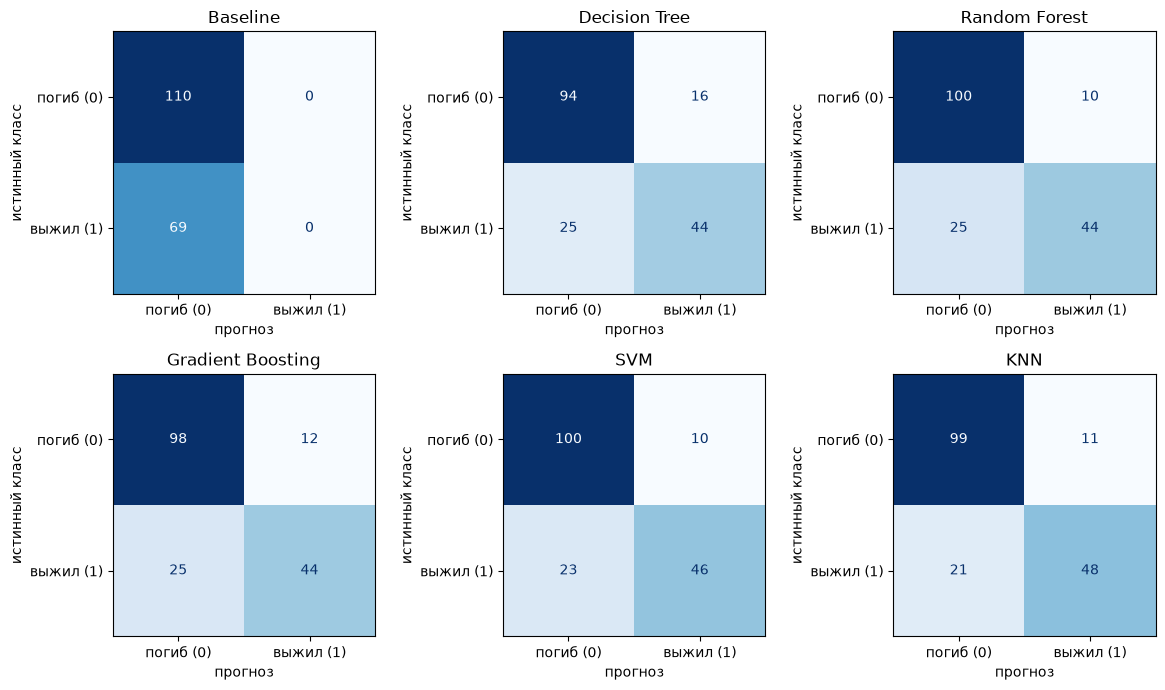

,TN,FP,FN,TP
Baseline,110,0,69,0
Decision Tree,94,16,25,44
Random Forest,100,10,25,44
Gradient Boosting,98,12,25,44
SVM,100,10,23,46
KNN,99,11,21,48


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for (name, pred), ax in zip(predictions.items(), axes.flat):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=['погиб (0)', 'выжил (1)'],
        ax=ax, colorbar=False, cmap='Blues',
    )
    ax.set(title=name, xlabel='прогноз', ylabel='истинный класс')
plt.tight_layout()
plt.show()

cm_rows = {}
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    cm_rows[name] = {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
cm_summary = pd.DataFrame(cm_rows).T
display(cm_summary)

**Выводы.** Baseline пропускает всех 69 выживших (FN). У каждой обученной модели FN больше, чем FP:
выживших чаще пропускают, чем ошибочно предсказывают выживание погибшим.
Дерево, лес и бустинг находят по 44 выживших, но дают соответственно 16, 10 и 12 FP.
Поэтому лес лучше этих двух моделей по Precision и F1. SVM находит 46 выживших, KNN — 48;
за счёт более высокого Recall KNN получает наибольший F1 на этом test.

## 8. Важность признаков

Для трёх моделей на деревьях использую встроенную важность — суммарное уменьшение нечистоты узлов.
Важности One-Hot столбцов суммирую по исходному признаку, чтобы сравнение было понятнее.
В каждой модели сумма важностей равна 1. Числовые признаки с большим числом значений могут получать завышенную важность;
связанные признаки могут подменять друг друга.

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.548,0.372,0.466
Fare,0.121,0.211,0.178
Age,0.103,0.184,0.150
Pclass,0.191,0.126,0.153
Embarked,0.035,0.040,0.022
SibSp,0.002,0.037,0.028
Parch,0.001,0.031,0.002


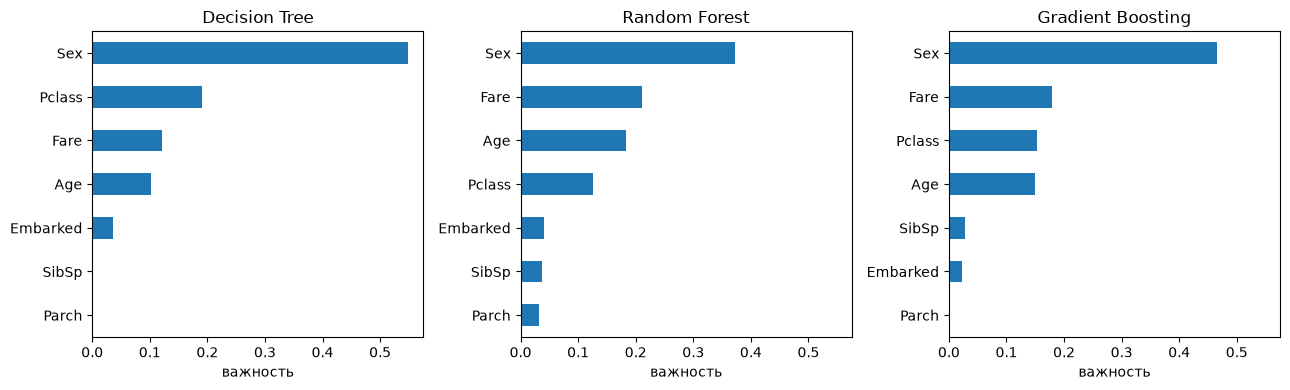

In [10]:
tree_names = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
importance = pd.DataFrame(index=features)
for name in tree_names:
    pipeline = fitted_models[name]
    transformed_names = pipeline[0].get_feature_names_out()
    original_names = [n.split('__', 1)[1].split('_', 1)[0] for n in transformed_names]
    values = pd.Series(pipeline[-1].feature_importances_, index=original_names)
    importance[name] = values.groupby(level=0).sum().reindex(features)

display(importance.sort_values('Random Forest', ascending=False).round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for name, ax in zip(tree_names, axes):
    importance[name].sort_values().plot.barh(ax=ax)
    ax.set(title=name, xlabel='важность')
plt.tight_layout()
plt.show()

**Выводы.** Во всех трёх моделях главный признак — `Sex` (важность 0.37–0.55), что согласуется с EDA.
Одиночное дерево затем выделяет `Pclass` (0.191), а лес — `Fare` (0.211) и `Age` (0.184).
У бустинга после пола идут `Fare` (0.178), `Pclass` (0.153) и `Age` (0.150).
Класс билета и возраст, выделенные в EDA, полезны и моделям; порядок остальных признаков различается,
поскольку модели строят разные разбиения и используют сочетания признаков. `Embarked`, `SibSp` и `Parch` имеют меньшую важность.

**Является ли важный признак причиной выживания?** По этой работе утверждать это нельзя.
Важность показывает полезность для прогноза в конкретной модели. Данные наблюдательные,
признаки связаны между собой и могут отражать другие условия эвакуации. Здесь нет эксперимента,
который позволил бы отделить причинный эффект от таких связей.

## 9. Анализ ошибок лучшей по CV модели

Анализирую модель, выбранную до просмотра test. Сравниваю число ошибок и их долю внутри групп:
большая группа может давать много ошибок просто из-за размера. Для каждой группы показываю и FP/FN.

In [11]:
best_pred = predictions[best_name]
tn, fp, fn, tp = confusion_matrix(y_test, best_pred, labels=[0, 1]).ravel()
print(f'{best_name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'Ошибка среди погибших: {fp / (tn + fp):.1%}; среди выживших: {fn / (tp + fn):.1%}')

errors = X_test.copy()
errors['true'] = y_test
errors['pred'] = best_pred
errors['error'] = errors['true'] != errors['pred']
errors['FP'] = (errors['true'] == 0) & (errors['pred'] == 1)
errors['FN'] = (errors['true'] == 1) & (errors['pred'] == 0)
errors['Age_group'] = pd.cut(
    errors['Age'], [0, 12, 18, 40, 60, np.inf], include_lowest=True,
).astype('string').fillna('возраст неизвестен')

for group in ['Sex', 'Pclass', 'Age_group']:
    print('Группы:', group)
    display(errors.groupby(group, observed=True).agg(
        count=('error', 'size'), errors=('error', 'sum'),
        error_rate=('error', 'mean'), FP=('FP', 'sum'), FN=('FN', 'sum'),
    ).round(3))

# По два примера каждого типа ошибки, в исходном порядке строк.
mistakes = pd.concat([
    errors.loc[errors['FP']].sort_index().head(2),
    errors.loc[errors['FN']].sort_index().head(2),
]).sort_index()
examples = mistakes[features + ['true', 'pred']].copy()
examples.insert(0, 'PassengerId (только для отчёта)', df.loc[examples.index, 'PassengerId'])
display(examples.round(2))

Gradient Boosting: TN=98, FP=12, FN=25, TP=44
Ошибка среди погибших: 10.9%; среди выживших: 36.2%
Группы: Sex
Группы: Pclass
Группы: Age_group


,count,errors,error_rate,FP,FN
Sex,,,,,
female,61,13,0.213,6,7
male,118,24,0.203,6,18


,count,errors,error_rate,FP,FN
Pclass,,,,,
1,45,12,0.267,6,6
2,34,4,0.118,1,3
3,100,21,0.210,5,16


,count,errors,error_rate,FP,FN
Age_group,,,,,
"(-0.001, 12.0]",14,4,0.286,1,3
"(12.0, 18.0]",17,1,0.059,0,1
"(18.0, 40.0]",79,16,0.203,3,13
"(40.0, 60.0]",23,5,0.217,3,2
"(60.0, inf]",6,1,0.167,0,1
возраст неизвестен,40,10,0.250,5,5


,PassengerId (только для отчёта),Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,true,pred
17,18,NaN,0,0,13.0,2,male,S,1,0
23,24,28.0,0,0,35.5,1,male,S,1,0
137,138,37.0,1,0,53.1,1,male,S,0,1
199,200,24.0,0,0,13.0,2,female,S,0,1


**Какие ошибки преобладают.** У выбранного по CV бустинга 25 FN против 12 FP:
пропущены 36.2% выживших, ошибочно названы выжившими 10.9% погибших. Основная проблема — недостаточный Recall.

**Группы.** По числу ошибок выделяются мужчины (24) и третий класс (21), но по доле ошибок
мужчины и женщины близки: 20.3% и 21.3%. Среди классов наибольшая доля ошибок у первого — 26.7% (12 из 45).
Среди возрастных групп заметны дети до 12 лет — 28.6% (4 из 14) и пассажиры с неизвестным возрастом — 25% (10 из 40).
Дети представлены малой группой, поэтому её процент неустойчив; пропущенный возраст уменьшает доступную модели информацию.

**Примеры ошибок из таблицы** (номера — `PassengerId`; объяснения являются гипотезами, а не доказанными причинами):

- **18, FN:** мужчина второго класса, возраст неизвестен. Модель могла опереться на низкую долю выживания мужчин;
  заполнение возраста медианой не восстанавливает настоящий возраст.
- **24, FN:** выживший мужчина первого класса, 28 лет. Высокий класс не компенсировал другие признаки в прогнозе;
  общая закономерность по полу не описывает каждого пассажира.
- **138, FP:** погибший мужчина первого класса с билетом за 53.1. Класс и стоимость могут быть благоприятными сигналами,
  но не определяют индивидуальный исход.
- **200, FP:** погибшая женщина второго класса, 24 года. Женщины в train обычно выживали,
  поэтому типичный для группы прогноз оказался неверен для этого пассажира.

В данных нет полного описания обстоятельств спасения. Поэтому одинаковые обычные характеристики не гарантируют одинакового исхода.

### Проверка нежелательных признаков

Высокое качество могло бы оказаться следствием запоминания ID, имён или билетов, либо попадания ответа в признаки.
Проверяю состав входа каждой обученной модели. ID в таблице ошибок нужен только для поиска пассажира в исходном CSV.

In [12]:
excluded = {'PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived'}
assert excluded.isdisjoint(X_train.columns)
print('Признаки моделей:', features)
print('Идентификаторы и целевая переменная исключены из входных признаков.')

Вход моделей: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked']
ID, имя, билет, каюта и ответ не входят в признаки; строки train/test не пересекаются.


**Вывод.** Прямых идентификаторов и признаков с известным исходом во входе нет; статистические преобразования обучаются внутри Pipeline.
Однако пассажиры из одной семьи могли оказаться в разных частях случайного разбиения и иметь похожие обычные признаки.
Эта оценка относится к заданному разбиению пассажиров и не доказывает качество на полностью новых семьях.

## 10. Итоговые выводы

- Подготовлены семь признаков; пропуски, категории и масштабирование обрабатываются внутри Pipeline без обучения на test.
  Все модели используют одно стратифицированное разбиение: 712 / 179 пассажиров.
- Построены baseline и все пять требуемых моделей; приведены четыре метрики, матрицы ошибок и важность признаков для трёх моделей на деревьях.
- По CV на train выбран **Gradient Boosting** (CV F1 = 0.753; test F1 = 0.704).
  Максимум F1 на локальном test — **KNN, 0.750**. Порог прошли четыре модели; дерево решений — нет.
- Пол — самый важный признак всех трёх моделей на деревьях; также полезны стоимость билета, класс и возраст.
  Эти связи не доказывают причинность. Главная ошибка выбранной модели — пропуск выживших.
- Результаты относятся к локальному test; качество на едином тесте группы этой работой не измерено.